# Solar filament segmentation: the whole pipeline

This notebook walks through the solution end to end and **rebuilds the submitted
predictions from the weights stored in this repository; nothing is retrained**.

1. Data and annotations
2. Preprocessing: limb fit and flat-fielding
3. The two networks on one frame: U-Net probability map and detector proposals
4. Candidates and expected-PQ selection on that frame
5. Full inference on the 180 test frames -> `submission.csv`, compared with the submitted file
6. Validation: out-of-fold Panoptic Quality, its uncertainty, and the organisers' diagnostic plots
7. How the weights were trained

**Requirements.** The competition data unpacked under `data/MAGFiLO_1.0_Kaggle_2026/`
(or set `FILASEG_DATA`), the packages in `requirements.txt`, and a GPU for section 5
(about one hour on a Tesla T4; sections 1-4 and 6 take a few minutes).

In [1]:
import json, os, sys, time
from pathlib import Path

REPO = Path.cwd() if (Path.cwd() / "filaseg").exists() else Path.cwd().parent
sys.path.insert(0, str(REPO))

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch

from filaseg import (candidates, config, data, detector, inference, metric, pipeline,
                     preprocess, reproduce, rle, selection, submission, unet)

WEIGHTS = REPO / "weights"
DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"
manifest = reproduce.load_manifest(WEIGHTS)
print("data   :", config.data_root())
print("device :", DEVICE)
print("U-Nets :", {k: len(v) for k, v in manifest["unets"].items()})
print("detectors:", {k: len(v["files"]) for k, v in manifest["detectors"].items()})

data   : D:\Competitions and Hackathons\filament-segmentation-2026\clean_solution\data\MAGFiLO_1.0_Kaggle_2026
device : cuda:0
U-Nets : {'r34': 4}
detectors: {'m1536': 4, 's1280': 4, 'm2048': 4}


## 1. Data and annotations

Each frame is a 2048 x 2048 H-alpha image of the full solar disk. A frame is drawn by one,
two or three annotators; each drawing is called a *view*. The organisers score a prediction
against every view separately, so the views are never merged. Annotators agree only partly:
scoring one annotator against the others of the same frame gives a Panoptic Quality of about
0.34 (computed in section 6), which is the yardstick for every number below.

707 training frames, 1154 views, 8199 drawn filaments
frames by number of annotators: {1: 411, 2: 145, 3: 151}
frames per fold: {0: 178, 1: 177, 2: 177, 3: 175}


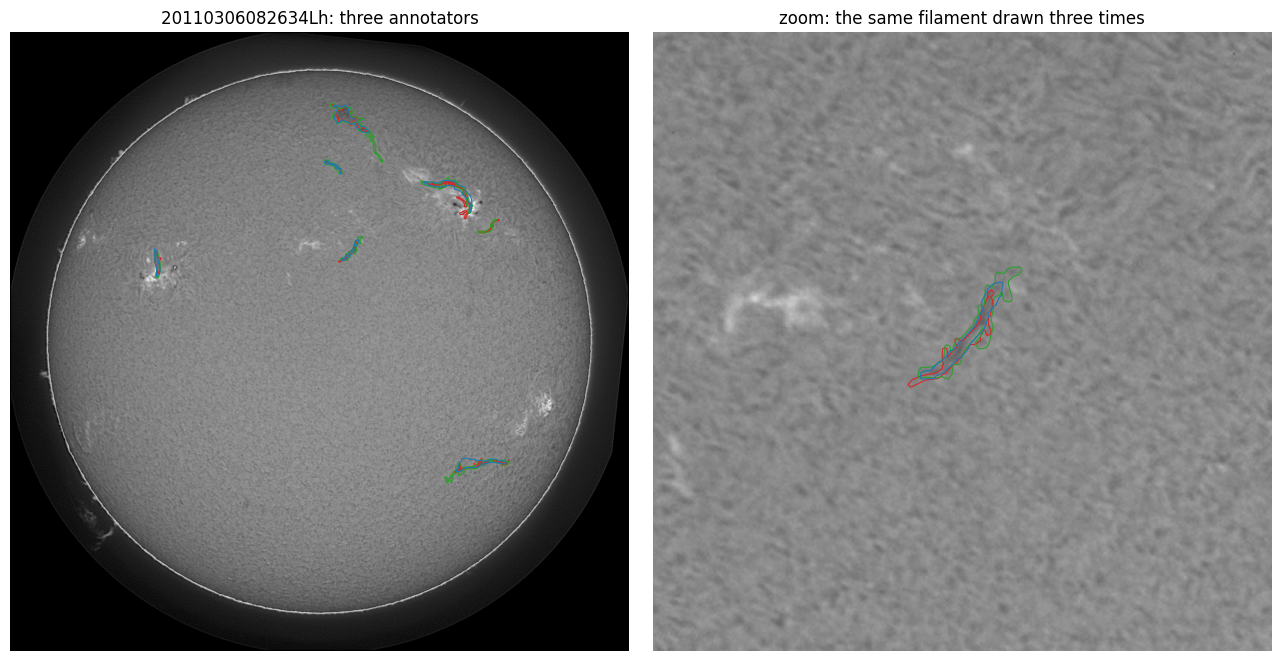

In [2]:
observations = data.load_observations()
fold_of = data.assign_folds(observations)
n_views = [len(o.views) for o in observations]
print(len(observations), "training frames,", sum(n_views), "views,",
      sum(len(v.polygons) for o in observations for v in o.views), "drawn filaments")
print("frames by number of annotators:", {k: n_views.count(k) for k in (1, 2, 3)})
print("frames per fold:", {k: sum(1 for f in fold_of.values() if f == k) for k in range(config.N_FOLDS)})

example = next(o for o in observations if len(o.views) == 3 and len(o.views[0].polygons) >= 6)
image = cv2.imread(str(data.image_path(example.stem, "train")), cv2.IMREAD_GRAYSCALE)
colours = ["tab:red", "tab:green", "tab:blue"]
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
axes[0].imshow(image, cmap="gray"); axes[0].set_title(f"{example.stem}: three annotators")
box = np.array(example.views[0].polygons[0]).reshape(-1, 2)
cx, cy = box.mean(axis=0); half = 220
axes[1].imshow(image, cmap="gray"); axes[1].set_xlim(cx - half, cx + half); axes[1].set_ylim(cy + half, cy - half)
axes[1].set_title("zoom: the same filament drawn three times")
for view, colour in zip(example.views, colours):
    for polygon in view.polygons:
        points = np.array(polygon).reshape(-1, 2)
        for ax in axes:
            ax.plot(points[:, 0], points[:, 1], color=colour, linewidth=0.8)
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

## 2. Preprocessing

`preprocess.fit_disk` locates the limb (steepest radial brightness drop along 360 rays, robust
circle fit). `preprocess.flat_field` divides the image by a smooth, disk-restricted background,
which removes limb darkening: 100 means "as bright as the surrounding quiet Sun".
The networks see the raw image, the flat-fielded image and the distance from the disk centre.

Disk(cx=1023.2074584960938, cy=1023.6231689453125, radius=902.4814453125)


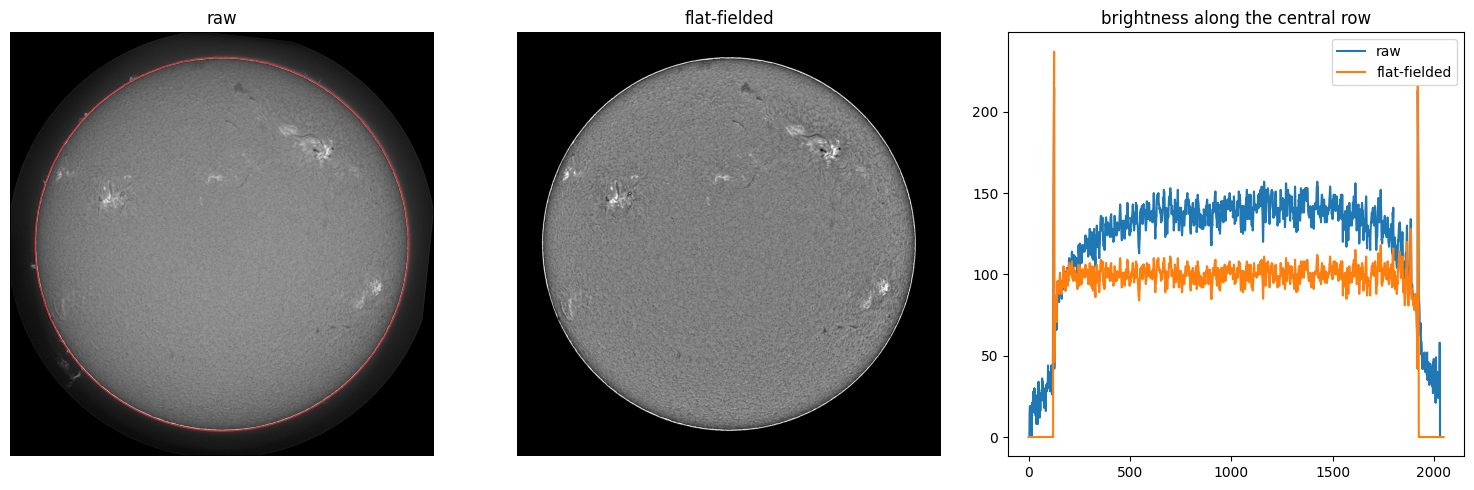

In [3]:
channels, disk = preprocess.build_channels(image)
print(disk)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(channels[0], cmap="gray"); axes[0].set_title("raw")
axes[0].add_patch(plt.Circle((disk.cx, disk.cy), disk.radius, fill=False, color="tab:red", linewidth=0.8))
axes[1].imshow(channels[1], cmap="gray", vmin=40, vmax=160); axes[1].set_title("flat-fielded")
axes[2].plot(channels[0][int(disk.cy)], label="raw"); axes[2].plot(channels[1][int(disk.cy)], label="flat-fielded")
axes[2].set_title("brightness along the central row"); axes[2].legend()
for ax in axes[:2]: ax.axis("off")
plt.tight_layout(); plt.show()

## 3. The two networks on one test frame

* **U-Net** (full resolution, 8 flips/rotations averaged): the probability that a pixel is
  filament. It gives accurate outlines but does not know which pixels belong together.
* **YOLO11-seg detectors** (whole disk, 4 mirror views): instance
  proposals with a confidence. It groups pixels into filaments but its masks are coarse.

20110706164014Mh: 5 fused detections, confidences [0.73, 0.66, 0.31, 0.14, 0.03] ...


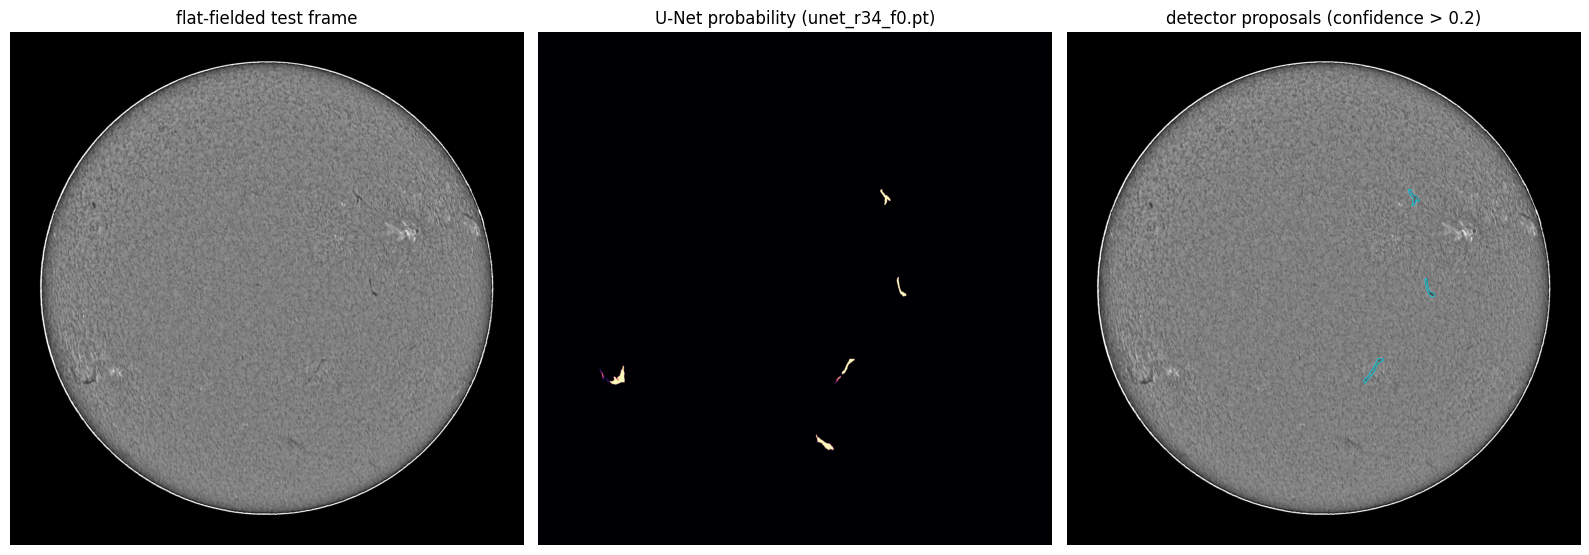

In [4]:
preprocess.build_cache("test", verbose=False)
test_stems = data.list_test_stems()
stem = test_stems[10]
test_channels = preprocess.load_channels(stem, "test")
test_disk = preprocess.load_disks("test")[stem]

unet_file = next(iter(manifest["unets"].values()))[0]
model = unet.load_model(WEIGHTS / unet_file, DEVICE)
probability = unet.predict_probability([model], test_channels, test_disk, device=DEVICE, tta=manifest["tta"])

det_name, det_spec = next(iter(manifest["detectors"].items()))
views = detector.predict(WEIGHTS / det_spec["files"][0], test_channels, imgsz=det_spec["imgsz"],
                         device=0 if DEVICE.startswith("cuda") else "cpu", flips=manifest["flips"])
detections = pipeline.merge_detections(views)
print(f"{stem}: {len(detections)} fused detections, confidences",
      [round(d['score'], 2) for d in detections[:8]], "...")

fig, axes = plt.subplots(1, 3, figsize=(16, 5.6))
axes[0].imshow(test_channels[1], cmap="gray", vmin=40, vmax=160); axes[0].set_title("flat-fielded test frame")
axes[1].imshow(probability, cmap="magma"); axes[1].set_title(f"U-Net probability ({unet_file})")
axes[2].imshow(test_channels[1], cmap="gray", vmin=40, vmax=160); axes[2].set_title("detector proposals (confidence > 0.2)")
for d in detections:
    if d["score"] > 0.2:
        contours, _ = cv2.findContours(rle.decode(d["rle"]).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        for c in contours:
            axes[2].plot(c[:, 0, 0], c[:, 0, 1], linewidth=0.7, color="tab:cyan")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Candidates and expected-PQ selection

A **candidate** is the U-Net foreground inside one (slightly grown) detector mask, at three
probability cuts. A small bag of gradient-boosted regressors predicts each candidate's **value**: its matched
IoU averaged over the annotators' views (0 where it matches nothing). Submitting a candidate
raises PQ exactly when its value exceeds half the current PQ (derivation in
`filaseg/selection.py`), so candidates are accepted greedily, best first, while their predicted
value clears a threshold and they do not overlap what is already accepted.

15 candidates -> 3 submitted instances (value threshold 0.26)


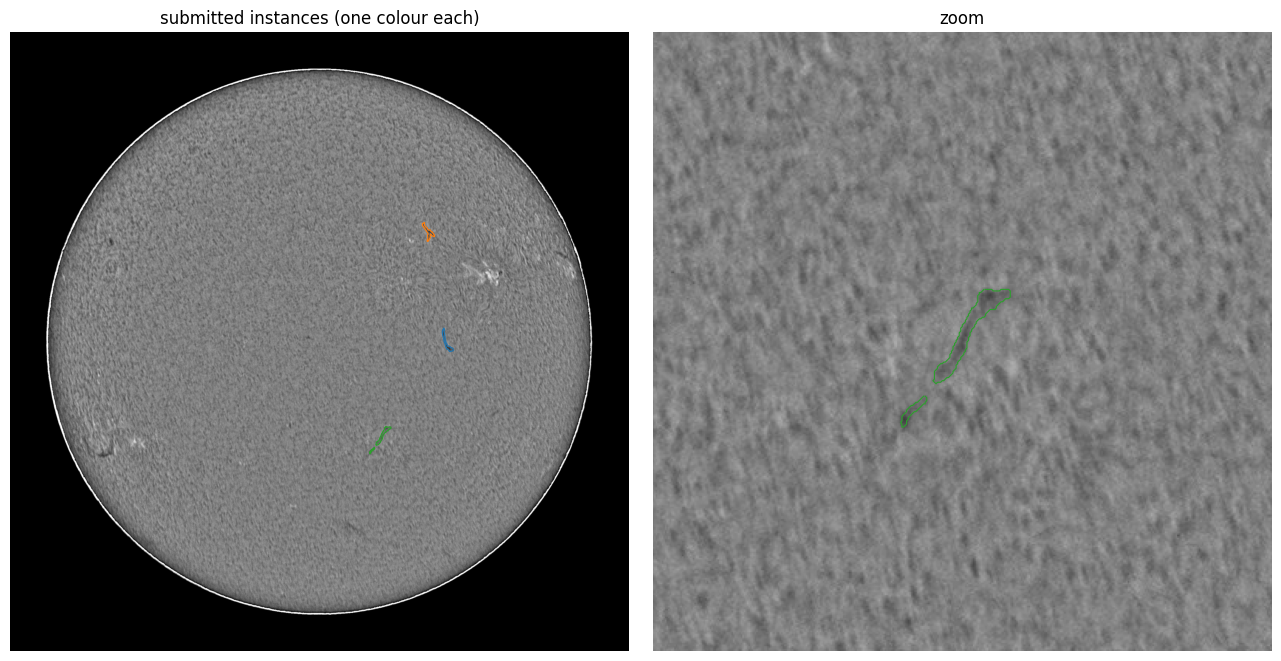

In [5]:
frame_candidates = candidates.generate(probability, detections, test_channels, test_disk)
scorer = selection.load_scorer(WEIGHTS / manifest["scorer"])
values = selection.predict_values(scorer, frame_candidates)
params = selection.SelectionParams(**manifest["selection"])
instances = selection.select(frame_candidates, values, params)
print(f"{len(frame_candidates)} candidates -> {len(instances)} submitted instances "
      f"(value threshold {params.value_threshold})")

ys, xs = np.nonzero(np.any(instances, axis=0)) if instances else (np.array([1024]), np.array([1024]))
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
for ax in axes:
    ax.imshow(test_channels[1], cmap="gray", vmin=40, vmax=160); ax.axis("off")
    for k, mask in enumerate(instances):
        contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        for c in contours:
            ax.plot(c[:, 0, 0], c[:, 0, 1], linewidth=0.8, color=plt.cm.tab10(k % 10))
axes[0].set_title("submitted instances (one colour each)")
biggest = max(instances, key=lambda m: m.sum()) if instances else None
if biggest is not None:
    by, bx = np.nonzero(biggest)
    axes[1].set_xlim(bx.mean() - 200, bx.mean() + 200); axes[1].set_ylim(by.mean() + 200, by.mean() - 200)
axes[1].set_title("zoom")
plt.tight_layout(); plt.show()

## 5. Full inference on the test set

`reproduce.make_submission` runs every released network over the 180 test frames, builds the
candidates, scores and selects them, and writes the submission file. The result is compared with
`results/final_submission.csv`, the file that was submitted to Kaggle. Small differences are
expected, because probabilities computed on a different GPU differ in the last bits and a few
pixels sit exactly on a threshold; the comparison reports how many instances agree.

In [6]:
started = time.time()
out_csv = config.out_root() / "submissions" / "submission.csv"
stats = reproduce.make_submission(WEIGHTS, out_csv, device=DEVICE)
print(json.dumps(stats, indent=2))
print(f"inference took {(time.time() - started) / 60:.1f} min -> {out_csv}")

  U-Net test: 25/180  60 s


  U-Net test: 50/180  120 s


  U-Net test: 75/180  181 s


  U-Net test: 100/180  242 s


  U-Net test: 125/180  300 s


  U-Net test: 150/180  358 s


... (125 outputs left out)

  selected 120 frames  113 s


  selected 150 frames  128 s


  selected 180 frames  143 s


{
  "rows": 1118,
  "frames_with_predictions": 177,
  "frames_total": 180,
  "median_area": 1280.0,
  "mean_per_frame": 6.211111111111111
}
inference took 155.1 min -> D:\Competitions and Hackathons\filament-segmentation-2026\clean_solution\outputs_nb\submissions\submission.csv


In [7]:
rebuilt = submission.read(out_csv)
submitted = submission.read(REPO / "results" / "final_submission.csv")
agreement = metric.Totals()
for stem in test_stems:
    agreement = agreement + metric.score_view(rebuilt.get(stem, []), submitted.get(stem, []))
print("rebuilt  :", sum(len(v) for v in rebuilt.values()), "instances")
print("submitted:", sum(len(v) for v in submitted.values()), "instances")
print("agreement (the submitted file used as ground truth):", agreement)

rebuilt  : 1118 instances
submitted: 1118 instances
agreement (the submitted file used as ground truth): PQ 0.9998  DQ 1.0000  SQ 0.9998  TP 1118  FP 0  FN 0


## 6. Validation

Everything in this section is **out-of-fold**: the training frames were split into four folds by
frame; a frame's prediction comes from networks, and from a selector, that were fitted without it.
`results/oof_predictions.csv` holds those predictions (written by `scripts/05_fit_selector.py`);
the cell below scores them with the organisers' rules and redraws the plots of their
self-evaluation notebook. The 95 % intervals resample frames 2000 times.

PQ 0.4550  95% CI 0.4459-0.4637  DQ 0.6671  SQ 0.6821  (707 frames)
  1 annotator(s): PQ 0.4563  (411 frames)
  2 annotator(s): PQ 0.4652  (145 frames)
  3 annotator(s): PQ 0.4470  (151 frames)
  annotator vs annotator: PQ 0.3399
  third annotator predicted by one_annotator: PQ 0.3334  (151 frames)
  third annotator predicted by two_annotators_agree: PQ 0.3226  (151 frames)
  third annotator predicted by method: PQ 0.4470  (151 frames)
wrote D:\Competitions and Hackathons\filament-segmentation-2026\clean_solution\outputs_nb\evaluation\metrics.json and figures



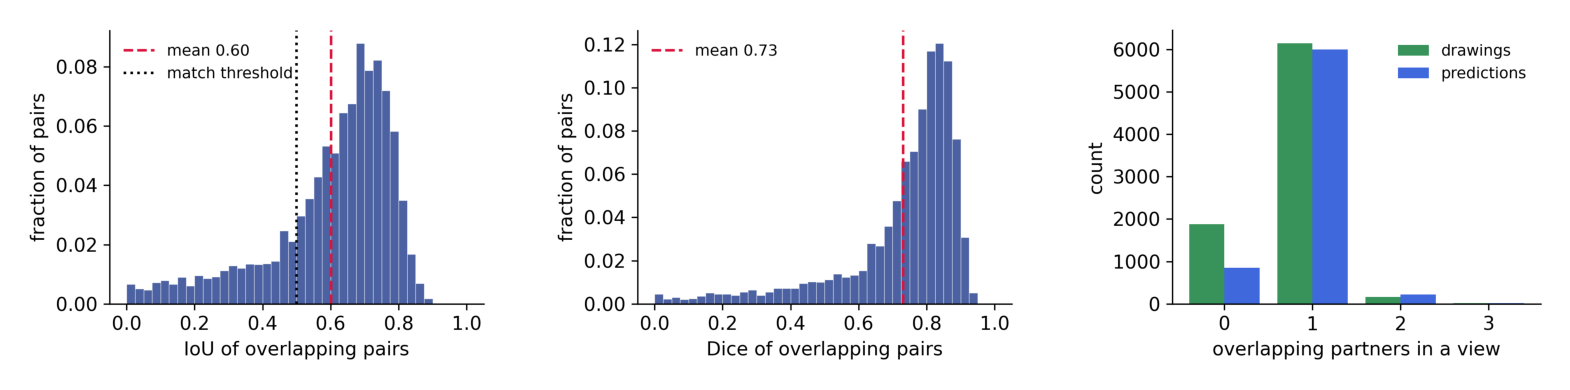

In [8]:
import subprocess
print(subprocess.run([sys.executable, str(REPO / "scripts" / "08_evaluate.py"),
                      "--predictions", str(REPO / "results" / "oof_predictions.csv"),
                      "--out", str(config.out_root() / "evaluation")],
                     capture_output=True, text=True).stdout)
report = json.load(open(config.out_root() / "evaluation" / "metrics.json"))
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, name in zip(axes, ("iou_distribution", "dice_distribution", "relations")):
    ax.imshow(plt.imread(config.out_root() / "evaluation" / f"{name}.png")); ax.axis("off")
plt.tight_layout(); plt.show()

In [9]:
rows = [("all frames", report["overall"])]
rows += [(f"{k} annotator(s)", v) for k, v in report["by_number_of_annotators"].items()]
rows += [(f"site {k}", v) for k, v in report["by_site"].items()]
rows += [("annotator vs annotator", report["annotator_vs_annotator"])]
print(f"{'subset':26s} {'frames':>6s} {'PQ':>7s} {'95% interval':>17s} {'DQ':>7s} {'SQ':>7s}")
for name, r in rows:
    low, high = r["ci95"]["pq"]
    print(f"{name:26s} {r['frames']:6d} {r['pq']:7.3f}   [{low:.3f}, {high:.3f}] {r['dq']:7.3f} {r['sq']:7.3f}")

subset                     frames      PQ      95% interval      DQ      SQ
all frames                    707   0.455   [0.446, 0.464]   0.667   0.682
1 annotator(s)                411   0.456   [0.445, 0.468]   0.662   0.689
2 annotator(s)                145   0.465   [0.446, 0.483]   0.682   0.682
3 annotator(s)                151   0.447   [0.432, 0.463]   0.662   0.676
site Bh                       118   0.461   [0.441, 0.479]   0.673   0.684
site Ch                       125   0.460   [0.441, 0.480]   0.679   0.678
site Lh                       127   0.446   [0.426, 0.467]   0.648   0.689
site Mh                       125   0.445   [0.423, 0.468]   0.659   0.676
site Th                       110   0.449   [0.423, 0.475]   0.658   0.683
site Uh                       102   0.470   [0.447, 0.492]   0.688   0.683
annotator vs annotator        296   0.340   [0.324, 0.356]   0.536   0.634


## 7. How the weights were trained

Nothing above trains a model. The released weights come from these commands (four folds,
`--fold 0..3`); `README.md` lists the hardware and the time each one took.

```bash
python scripts/01_preprocess.py
python scripts/02_train_unet.py     --fold 0 --name r34   --encoder resnet34 --iterations 12000 --batch-size 12
python scripts/03_train_detector.py --fold 0 --name m1536 --weights yolo11m-seg.pt --imgsz 1536 --epochs 80 --batch 2
python scripts/03_train_detector.py --fold 0 --name s1280 --weights yolo11s-seg.pt --imgsz 1280 --epochs 60 --batch 4
python scripts/03_train_detector.py --fold 0 --name m2048 --weights yolo11m-seg.pt --imgsz 2048 --epochs 45 --batch 1 --mask-ratio 4
python scripts/04_build_candidates.py --name main --unets r34 --detectors m1536 s1280 m2048
python scripts/05_fit_selector.py     --name main
python scripts/06_make_submission.py  --name main
```